In [1]:
import os
import sys


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Line3DCollection
import seaborn as sns
import random
from pathlib import Path
from numpy.linalg import norm
import datetime
import math
import multiprocess as mp
import time
import pickle
import pyarrow.feather as feather
from scipy.signal import savgol_filter


In [2]:
DATADIR = Path.cwd().joinpath("lyaps")

lyaps_df_orig_dmso = feather.read_feather(Path(DATADIR, 'lyaps_dmso_orig.fea'))
# int_dmso = feather.read_feather(Path(DATADIR, 'mIMT_dmso_orig.fea'))
lyaps_df_orig_erl = feather.read_feather(Path(DATADIR, 'lyaps_erl_orig.fea'))
# int_erl = feather.read_feather(Path(DATADIR, 'mIMT_erl.fea'))

In [3]:
def get_avgs(lyaps_df):
    all_lyap_avgs = []
    for row in range(len(lyaps_df)):
        tmp_pos = lyaps_df.iloc[row,:]
        lyap_avgs=[]
        for posit in range(len(tmp_pos[1])):
            d=[]
            for i in range(len(tmp_pos)):
                i+=1
                d.append(tmp_pos[i][posit])
            lyap_avgs.append(sum(d)/len(d))   
        all_lyap_avgs.append(lyap_avgs)
    
    return all_lyap_avgs

def fit_lyap(lyap_trace):
    t = np.linspace(0, 1000, 501)
    max_t=np.argmax(lyap_trace)
    #np.argmin(results[1][1][tmp:])
    min_t = min(lyap_trace[max_t:])
    min_r = math.ceil(min_t*10)/10
    min_inds = [i for i,v in enumerate(lyap_trace) if v <= min_r]
    if min_inds[0] > max_t:
        coef = np.polyfit(t[max_t:min_inds[0]],lyap_trace[max_t:min_inds[0]],1)
        poly1d_fn = np.poly1d(coef)   
    else:
        coef = np.polyfit(t,lyap_trace,1)
        poly1d_fn = np.poly1d(coef)   
    return coef[0]

In [4]:
all_lyap_avgs_orig_dmso = get_avgs(lyaps_df_orig_dmso)
all_lyap_avgs_orig_erl = get_avgs(lyaps_df_orig_erl)

In [5]:
all_lyap_fits_orig_dmso = []
for lyap in all_lyap_avgs_orig_dmso:
    all_lyap_fits_orig_dmso.append(fit_lyap(lyap)) 
    
all_lyap_fits_orig_erl = []
for lyap in all_lyap_avgs_orig_erl:
    all_lyap_fits_orig_erl.append(fit_lyap(lyap)) 


In [6]:
stiff = np.linspace(0,1,100)


(-0.1, 0.02)

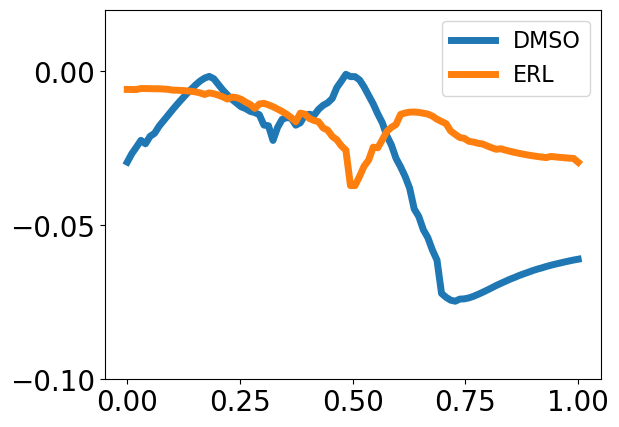

In [7]:
lyap_dmso2 = np.genfromtxt(Path('lyap_dmso.csv'), delimiter=',')
lyap_erl2 = np.genfromtxt(Path('lyap_erl.csv'), delimiter=',')


params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 24,
         'axes.titlesize': 24,
         'axes.edgecolor': "black",
         'xtick.labelsize': 20,
         'ytick.labelsize': 20}
plt.rcParams.update(params)

plt.plot(stiff, lyap_dmso2, label="DMSO", lw=5)
plt.plot(stiff, lyap_erl2, label='ERL', lw=5)
plt.legend(fontsize=16)
locs, labels = plt.xticks() 
plt.xticks([0, 0.25, 0.5, 0.75, 1])
plt.yticks([-0.1, -0.05, 0])

plt.ylim(-0.1, 0.02)

### First value of preprocessed data
Data from `lyap_erl.csv`

In [11]:
lyap_erl2[0]

-0.0058984678773246

### First value from fits generated in this notebook
Data saved in `all_lyap_avgs_orig_erl`

In [14]:
all_lyap_fits_orig_erl[0]

-0.00446295637763476